# HAADF PnP-Flow Inpainting

This notebook loads a HAADF frame from HDF5, uses an explicit damage mask, and reconstructs only masked pixels with the ten-category SEM flow-matching prior. It never changes observed pixels.

In [5]:
from pathlib import Path
import os
import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch

from pnpflow.degradations import FixedMaskInpainting
from pnpflow.utils import define_model

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks/ directory.')
os.chdir(repo_root)

# Use the separate all-ten-category SEM training run as the image prior.
DATASET_NAME = 'sem_nffa_all10'
model_root = repo_root / 'model' / DATASET_NAME / 'ot'
RUN_NAME = '20260713_112747_sem_nffa_all10_ot'
run_dir = model_root / RUN_NAME
assert run_dir.is_dir(), f'SEM run not found: {run_dir}'
checkpoint_path = run_dir / 'model_final.pt'
if not checkpoint_path.is_file():
    periodic_checkpoints = sorted(run_dir.glob('model_*.pt'), key=lambda path: int(path.stem.split('_')[1]))
    if not periodic_checkpoints:
        raise FileNotFoundError(f'No completed SEM checkpoint found in {run_dir}')
    checkpoint_path = periodic_checkpoints[-1]
assert checkpoint_path.is_file(), f'Checkpoint not found: {checkpoint_path}'

# Use CPU while the four-GPU SEM training job is active; set True after GPUs are free.
USE_CUDA = True
device = torch.device('cuda' if USE_CUDA and torch.cuda.is_available() else 'cpu')

class HAADFModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = 128

model, _ = define_model(HAADFModelArgs())
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.to(device).eval()
print(f'Loaded ten-category SEM prior: {checkpoint_path} on {device}')

Loaded ten-category SEM prior: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10/ot/20260713_112747_sem_nffa_all10_ot/model_final.pt on cuda


In [2]:
# Select either content/HAADF_21.h5 or content/graphene_2.h5.
HAADF_H5 = Path.home() / 'projects/microscopic_inpainting/content/graphene_2.h5'
HAADF_DATASET_PATH = 'Measurement_000/Channel_000/HAADF/HAADF'

# Preferred: a same-sized .npy boolean or 0/1 mask. True/nonzero means beam-damaged and missing.
MISSING_MASK_PATH = None  # Example: HAADF_H5.with_name('graphene_2_damage_mask.npy')
# A controlled synthetic test only. Each entry is (top, left, bottom, right).
SYNTHETIC_MISSING_BOXES = [(960, 960, 1888, 1888)]  # Controlled synthetic test.

with h5py.File(HAADF_H5, 'r') as handle:
    raw = handle[HAADF_DATASET_PATH][()].astype(np.float32)
if raw.ndim != 2 or not np.isfinite(raw).all():
    raise ValueError(f'Expected a finite 2D HAADF frame, got {raw.shape}')

if MISSING_MASK_PATH is not None:
    missing = np.load(MISSING_MASK_PATH).astype(bool)
    if missing.shape != raw.shape:
        raise ValueError(f'Mask shape {missing.shape} does not match image shape {raw.shape}')
else:
    missing = np.zeros_like(raw, dtype=bool)
    for top, left, bottom, right in SYNTHETIC_MISSING_BOXES:
        missing[top:bottom, left:right] = True

if not missing.any():
    raise ValueError('Set MISSING_MASK_PATH or SYNTHETIC_MISSING_BOXES before inpainting.')

# Normalize from observed pixels only, so damaged values cannot affect scaling.
low, high = np.percentile(raw[~missing], (1, 99))
if not high > low:
    raise ValueError('Observed pixels have no usable intensity range.')
image_norm = 2 * np.clip((raw - low) / (high - low), 0, 1) - 1
print(f'Image shape: {raw.shape}; missing fraction: {missing.mean():.2%}')
print(f'Observed-pixel range: [{low:.5g}, {high:.5g}]')

Image shape: (2048, 2048); missing fraction: 20.53%
Observed-pixel range: [6096.2, 49101]


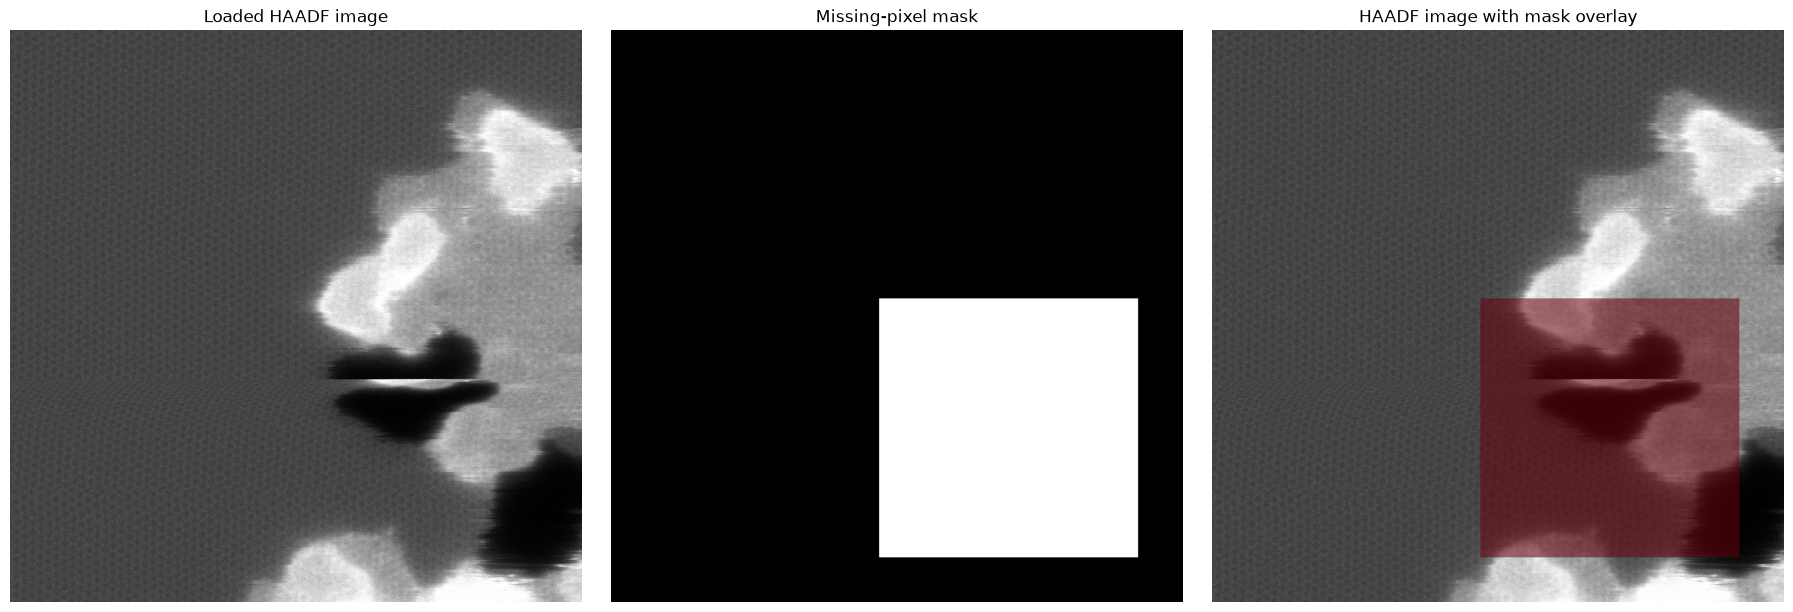

In [3]:
from pathlib import Path
import os
import h5py
import matplotlib.pyplot as plt
import numpy as np
import torch

display_low, display_high = np.percentile(raw, (1, 99))
masked_overlay = np.ma.masked_where(~missing, missing)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(raw, cmap='gray', vmin=display_low, vmax=display_high)
axes[0].set_title('Loaded HAADF image')

axes[1].imshow(missing, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Missing-pixel mask')

axes[2].imshow(raw, cmap='gray', vmin=display_low, vmax=display_high)
axes[2].imshow(masked_overlay, cmap='Reds', vmin=0, vmax=1, alpha=0.55)
axes[2].set_title('HAADF image with mask overlay')

for axis in axes:
    axis.axis('off')
plt.show()

In [4]:
# Multi-GPU inference setup. Run this after loading `model` and before the reconstruction cell.
# `torchlearn` currently exposes four Tesla V100 GPUs to PyTorch.
USE_MULTI_GPU = True
GPU_IDS = list(range(torch.cuda.device_count()))  # Logical CUDA IDs visible to this notebook kernel.

if USE_MULTI_GPU and device.type == 'cuda' and len(GPU_IDS) > 1:
    if not isinstance(model, torch.nn.DataParallel):
        model = torch.nn.DataParallel(model, device_ids=GPU_IDS, output_device=GPU_IDS[0])
    print(f'Multi-GPU inference enabled on {len(GPU_IDS)} GPUs: {GPU_IDS}')
else:
    print(f'Single-device inference on {device}')

# DataParallel splits every inference batch across GPU_IDS. Keep INFERENCE_BATCH_SIZE
# large enough to give each GPU useful work; tune it in the next cell for available VRAM.


Multi-GPU inference enabled on 4 GPUs: [0, 1, 2, 3]


Saved: /home/bselvaku/projects/microscopic_inpainting/content/graphene_2_pnp_flow_20260713_112747_sem_nffa_all10_ot_inpainted.npy


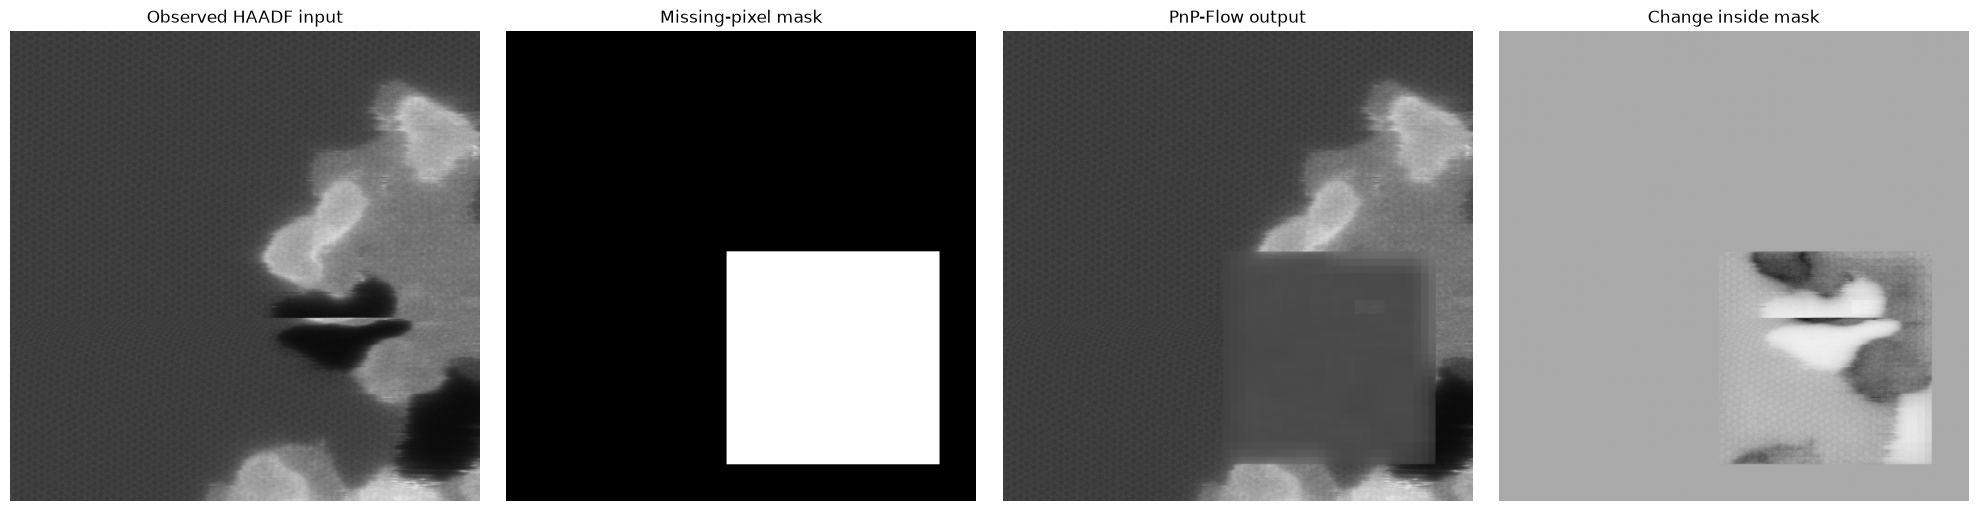

In [9]:
TILE_SIZE = 128
TILE_STRIDE = 32
INFERENCE_BATCH_SIZE = 2400
SIGMA = 0.01
STEPS_PNP = 200
NUM_SAMPLES = 1

@torch.no_grad()
def reconstruct_tiles(observed, known_mask):
    degradation = FixedMaskInpainting(known_mask)
    x = degradation.H_adj(observed).clone()
    known = degradation.H_adj(torch.ones_like(observed))
    for iteration in range(STEPS_PNP):
        t = torch.full((len(x),), iteration / STEPS_PNP, device=device)
        lr_t = (SIGMA ** 2) * (1 - t).view(-1, 1, 1, 1)
        z = x - lr_t * degradation.H_adj(degradation.H(x) - observed) / (SIGMA ** 2)
        x_new = torch.zeros_like(x)
        for _ in range(NUM_SAMPLES):
            z_tilde = t.view(-1, 1, 1, 1) * z + (1 - t).view(-1, 1, 1, 1) * torch.randn_like(z)
            x_new += z_tilde + (1 - t).view(-1, 1, 1, 1) * model(z_tilde, t)
        x = known * observed + (1 - known) * (x_new / NUM_SAMPLES)
    return x.clamp(-1, 1)

def tile_starts(length):
    if length <= TILE_SIZE:
        return [0]
    starts = list(range(0, length - TILE_SIZE + 1, TILE_STRIDE))
    if starts[-1] != length - TILE_SIZE:
        starts.append(length - TILE_SIZE)
    return starts

def inpaint_masked_only(image, missing_mask):
    height, width = image.shape
    padded_height, padded_width = max(height, TILE_SIZE), max(width, TILE_SIZE)
    pad = ((0, padded_height - height), (0, padded_width - width))
    image_pad = np.pad(image, pad, mode='reflect')
    missing_pad = np.pad(missing_mask, pad, mode='constant', constant_values=False)
    locations = [(top, left) for top in tile_starts(padded_height) for left in tile_starts(padded_width)
                 if missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE].any()]
    total = np.zeros_like(image_pad, dtype=np.float32)
    count = np.zeros_like(image_pad, dtype=np.float32)

    for start in range(0, len(locations), INFERENCE_BATCH_SIZE):
        batch_locations = locations[start:start + INFERENCE_BATCH_SIZE]
        tiles = np.stack([image_pad[top:top + TILE_SIZE, left:left + TILE_SIZE] for top, left in batch_locations])
        tile_masks = np.stack([missing_pad[top:top + TILE_SIZE, left:left + TILE_SIZE] for top, left in batch_locations])
        observed = torch.from_numpy(tiles[:, None]).float().to(device)
        known = torch.from_numpy((~tile_masks)[:, None].astype(np.float32)).to(device)
        restored_tiles = reconstruct_tiles(observed, known).cpu().numpy()[:, 0]
        for restored, tile_mask, (top, left) in zip(restored_tiles, tile_masks, batch_locations):
            target = np.s_[top:top + TILE_SIZE, left:left + TILE_SIZE]
            weights = tile_mask.astype(np.float32)
            total[target] += restored * weights
            count[target] += weights

    output = image_pad.copy()
    update = count > 0
    output[update] = total[update] / count[update]
    return output[:height, :width]

restored_norm = inpaint_masked_only(image_norm, missing)
# Mandatory final data consistency: all measured pixels remain exactly as supplied.
restored_norm[~missing] = image_norm[~missing]
restored_raw = raw.copy()
restored_raw[missing] = ((restored_norm[missing] + 1) * 0.5 * (high - low) + low)
assert np.array_equal(restored_raw[~missing], raw[~missing])

output_path = HAADF_H5.with_name(f'{HAADF_H5.stem}_pnp_flow_{RUN_NAME}_inpainted.npy')
np.save(output_path, restored_raw)
print(f'Saved: {output_path}')

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
views = [raw, missing, restored_raw, np.where(missing, restored_raw - raw, 0)]
titles = ['Observed HAADF input', 'Missing-pixel mask', 'PnP-Flow output', 'Change inside mask']
for axis, view, title in zip(axes, views, titles):
    axis.imshow(view, cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

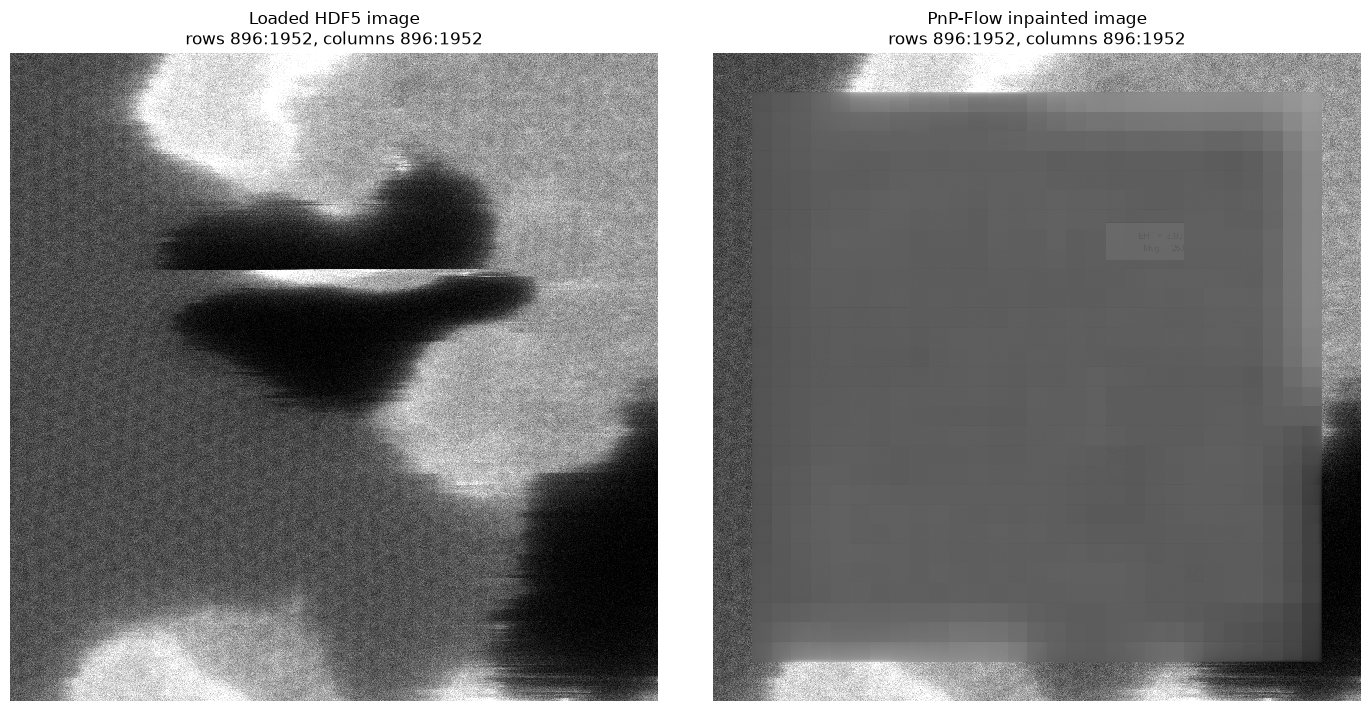

In [10]:
# Zoomed comparison of the HDF5 image and the reconstruction for the inpainted region.
# The current synthetic mask covers rows 960:1888 and columns 960:1888.
ZOOM_MARGIN = 64  # Context pixels shown around the missing region.

missing_rows, missing_cols = np.where(missing)
top = max(0, missing_rows.min() - ZOOM_MARGIN)
bottom = min(raw.shape[0], missing_rows.max() + 1 + ZOOM_MARGIN)
left = max(0, missing_cols.min() - ZOOM_MARGIN)
right = min(raw.shape[1], missing_cols.max() + 1 + ZOOM_MARGIN)
zoom = np.s_[top:bottom, left:right]

raw_zoom = raw[zoom]
restored_zoom = restored_raw[zoom]
vmin, vmax = np.percentile(raw_zoom, (1, 99))

fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
for axis, image, title in zip(
    axes,
    (raw_zoom, restored_zoom),
    ('Loaded HDF5 image', 'PnP-Flow inpainted image'),
):
    axis.imshow(image, cmap='gray', vmin=vmin, vmax=vmax, interpolation='nearest')
    axis.set_title(f'{title}\nrows {top}:{bottom}, columns {left}:{right}')
    axis.axis('off')

plt.show()


Raw image: /data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_4d65d0cb7d7ef11cf5f0c6e908d7ffee.jpg
X size (width): 1024 pixels; Y size (height): 768 pixels
Derived patch: x=116:244, y=255:383; shape=(128, 128)


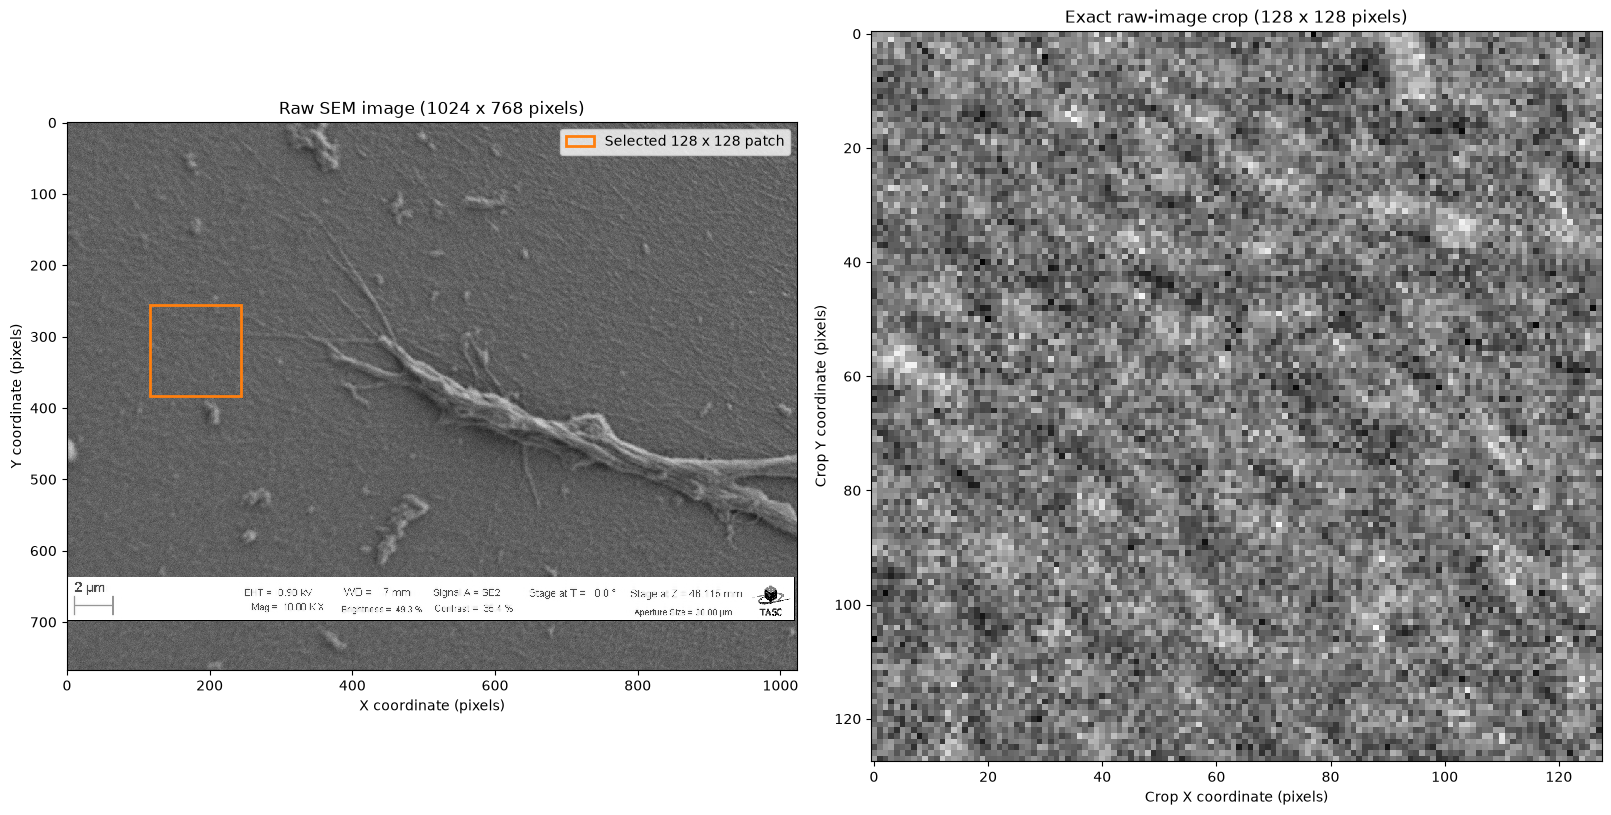

In [6]:
# Load and display the original SEM JPEG that produced the selected 128 x 128 test patch.
# The manifest links the derived .npy patch to its raw-image source and crop coordinates.
import csv
from PIL import Image
from matplotlib.patches import Rectangle

RAW_SEM_ROOT = Path('/data2/marci/bselvaku/nffa_sem/raw_images')
SEM_MANIFEST = Path('/data2/marci/bselvaku/nffa_sem/patches_128_all10/patch_manifest.csv')
SEM_PATCH = Path('test/Biological_0ee208e9120f_00.npy')

with SEM_MANIFEST.open(newline='', encoding='utf-8') as handle:
    patch_record = next(
        (row for row in csv.DictReader(handle) if row['patch'] == SEM_PATCH.as_posix()),
        None,
    )
if patch_record is None:
    raise FileNotFoundError(f'{SEM_PATCH} was not found in {SEM_MANIFEST}')

raw_sem_path = RAW_SEM_ROOT / patch_record['source']
with Image.open(raw_sem_path) as image:
    raw_sem = np.asarray(image.convert('L'))

height, width = raw_sem.shape
patch_x, patch_y = int(patch_record['x']), int(patch_record['y'])
patch_size = int(patch_record['patch_size'])
raw_sem_crop = raw_sem[patch_y:patch_y + patch_size, patch_x:patch_x + patch_size]
print(f'Raw image: {raw_sem_path}')
print(f'X size (width): {width} pixels; Y size (height): {height} pixels')
print(f'Derived patch: x={patch_x}:{patch_x + patch_size}, y={patch_y}:{patch_y + patch_size}; shape={raw_sem_crop.shape}')

fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
axes[0].imshow(raw_sem, cmap='gray', origin='upper', interpolation='nearest')
axes[0].add_patch(Rectangle((patch_x, patch_y), patch_size, patch_size,
                            fill=False, edgecolor='tab:orange', linewidth=2,
                            label='Selected 128 x 128 patch'))
axes[0].set_title(f'Raw SEM image ({width} x {height} pixels)')
axes[0].set_xlabel('X coordinate (pixels)')
axes[0].set_ylabel('Y coordinate (pixels)')
axes[0].legend(loc='upper right')

axes[1].imshow(raw_sem_crop, cmap='gray', origin='upper', interpolation='nearest')
axes[1].set_title(f'Exact raw-image crop ({patch_size} x {patch_size} pixels)')
axes[1].set_xlabel('Crop X coordinate (pixels)')
axes[1].set_ylabel('Crop Y coordinate (pixels)')
plt.show()
